# 03 · Models: linear baseline and multimodal neural network

**Research question.** Which features explain the asking prices of houses for sale in Zimbabwe, and how accurately can a model predict them?

This notebook fits and evaluates the models for the 2,283 cleaned houses from `02_cleaning_and_exploration.ipynb`. It compares, on data the models never saw:

| # | Model | What it uses |
|---|---|---|
| 1 | **Linear regression** (the baseline) | size, rooms, amenity count and area |
| 2 | Ridge regression | all structured (tabular) features |
| 3 | Gradient boosting | all structured features (a strong non-deep reference) |
| 4 | Ridge, all data types | structured features + photo features + text features |
| 5 | Neural network, tabular only | all structured features |
| 6 | Neural network + photos | structured + house photos (pretrained CNN) |
| 7 | Neural network + text | structured + descriptions (pretrained transformer embeddings) |
| 8 | **Multimodal neural network** | structured + photos + text |

Models 5 to 8 differ only in which data they receive, so the comparison shows what the photos and the descriptions add.

**Before running:** run `python extract_features.py` once. It turns the photos and descriptions into numbers with pretrained models and saves them in `data/image_features.npz` and `data/text_features.npz`. This notebook loads those files, so it does not need the photos.

## Design choices and why

**Target: `log_price`.** Prices are strongly right-skewed (see notebook 02), the effect of a feature is closer to a percentage than to a fixed amount of dollars, and squared errors on raw prices would be dominated by a few very expensive houses. Predictions are converted back with `exp()` and errors are reported on both scales.

**Honest evaluation.**
* The houses are split once into **70% train, 15% validation, 15% test**, stratified by price decile so each part has the same spread of prices. The validation set is only used to stop network training at the right time and to choose the best model; the **test set is used once, for the final numbers**.
* Everything that learns from data (the missing-value fill-ins, scaling, one-hot encoding, PCA) is fitted on the **training rows only**. This removes the small leakage that notebook 02 warned about.
* **5-fold cross-validation** on train + validation shows how stable each model's score is.
* Columns made from the price are never used as inputs (for example `price_outlier_flag`).

**Photos (the CNN branch).** Training a CNN from scratch on about 1,600 training photos, or even fine-tuning a large one, mostly memorises the training houses. Instead, each photo goes once through **ResNet-50 pretrained on ImageNet** (millions of photos), whose weights are *frozen*; its 2,048-number summary of the photo is averaged over each house's first five photos. The trainable part of the network learns which of those summary numbers matter for price. This is a standard, well-justified approach for small datasets.

**Descriptions.** Each description is turned into 384 numbers by a **pretrained sentence transformer** (`all-MiniLM-L6-v2`). **Amounts of money are masked first**, because many adverts quote the asking price (see the leakage check below).

**Architecture.** One small branch per data type (a dense layer with dropout), the branch outputs are concatenated, and a small head predicts the standardised log price. Dropout, weight decay and early stopping keep it from overfitting a small dataset, and each network is trained with several random seeds whose predictions are averaged.

## 0 · Setup

In [1]:
import os, re, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 170)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})

# ---- find the project folder (the one that has zim_property_data/ or data/) and work from there
PROJECT_ROOT = None      # if the notebook cannot find it by itself, put the folder here, e.g. "C:/house_project"
def find_project_root():
    if PROJECT_ROOT:
        return PROJECT_ROOT
    here = os.path.abspath(os.getcwd())
    folders = [here]
    for _ in range(3):
        folders.append(os.path.dirname(folders[-1]))
    for folder in folders:
        if os.path.exists(os.path.join(folder, "data", "houses_clean.csv")):
            return folder
    raise FileNotFoundError(f"Could not find data/houses_clean.csv from {here}. Run notebook 02 first, "
                            "or set PROJECT_ROOT in this cell to your project folder, e.g. PROJECT_ROOT = 'C:/house_project'.")
os.chdir(find_project_root())
sys.path.insert(0, os.getcwd())          # so that text_utils.py (in the project folder) can be imported
print("Working folder:", os.getcwd())
DATA, FIG, TAB = "data", "figures", "tables"
for folder in (FIG, TAB):
    os.makedirs(folder, exist_ok=True)

# ---- PyTorch is only needed for the neural networks (models 5-8)
try:
    import torch, torch.nn as nn
    torch.set_num_threads(max(1, (os.cpu_count() or 2) - 1))
    RUN_NN = True
    print("PyTorch", torch.__version__)
except ImportError:
    RUN_NN = False
    print("PyTorch is not installed: models 1-4 will run, the neural networks (5-8) will be skipped. Install it with: pip install torch")

# ---- settings
QUICK = False            # True = fast test run (1 seed, short training, no cross-validation). Use False for the final results.
SEED = 42
TEST_SIZE, VAL_SIZE = 0.15, 0.15
IMG_PCA, TXT_PCA = 64, 32                            # photo / text features are reduced to this many numbers (PCA, fitted on training rows)
N_SEEDS, RUN_CV, CV_FOLDS = (1, False, 5) if QUICK else (5, True, 5)
HIDDEN, DROPOUT, LR, WEIGHT_DECAY, BATCH = 128, 0.3, 1e-3, 1e-4, 64
MAX_EPOCHS, PATIENCE = (40, 10) if QUICK else (300, 30)
np.random.seed(SEED)

def save_show(name):
    plt.tight_layout(); plt.savefig(os.path.join(FIG, name), bbox_inches="tight"); plt.show()

Working folder: C:\house_project
PyTorch 2.15.0+cpu


## 1 · Load the data

The cleaned houses, plus the photo and text features saved by `extract_features.py` (one row of numbers per house). Houses whose photos could not be downloaded have no photo features; they get a `has_photo = 0` flag and a neutral (average) photo vector.

In [2]:
houses = pd.read_csv(os.path.join(DATA, "houses_clean.csv"), low_memory=False)
y = houses["log_price"].to_numpy()

def load_features(name, ids):
    path = os.path.join(DATA, name)
    if not os.path.exists(path):
        raise FileNotFoundError(f"{path} not found. Run  python extract_features.py  once from the project folder first.")
    z = np.load(path)
    table = pd.DataFrame(z["features"], index=z["ids"].astype(str))
    valid = ids.isin(table.index).to_numpy()
    out = np.zeros((len(ids), table.shape[1]), dtype=np.float32)
    out[valid] = table.loc[ids[valid]].to_numpy()
    n_used = pd.Series(z["n_used"], index=z["ids"].astype(str)).reindex(ids).fillna(0).to_numpy() if "n_used" in z.files else valid.astype(int)
    return out, valid, n_used

ids = houses["listing_id"].astype(str)
img_raw, img_found, n_photos_used = load_features("image_features.npz", ids)
txt_raw, txt_found, _ = load_features("text_features.npz", ids)
has_photo = img_found & (n_photos_used > 0)
houses["has_photo"] = has_photo.astype(int)

print(f"{len(houses):,} houses | photo features: {img_raw.shape[1]} numbers for {int(has_photo.sum()):,} houses "
      f"(mean {n_photos_used[has_photo].mean():.1f} photos each) | text features: {txt_raw.shape[1]} numbers for {int(txt_found.sum()):,} houses")

2,283 houses | photo features: 2048 numbers for 2,268 houses (mean 4.9 photos each) | text features: 384 numbers for 2,283 houses


### Leakage check: prices written inside the adverts

Agents often quote the price in the advert ("Asking US$120,000"). If that text were given to a text model it could just read the answer. The check below counts houses whose title/description contains a number within 2% of the asking price, before and after masking amounts of money. `extract_features.py` uses the masked text.

In [3]:
from text_utils import mask_prices, leaks_price

text = houses["title"].fillna("") + ". " + houses["description"].fillna("")
masked = text.map(mask_prices)
before = sum(leaks_price(t, p) for t, p in zip(text, houses["price_usd"]))
after = sum(leaks_price(t, p) for t, p in zip(masked, houses["price_usd"]))
print(f"Houses whose text contains the asking price: {before} ({before / len(houses):.1%}) before masking, {after} after masking.")
print("\nExample of a masked advert:")
example = houses.index[text.str.contains(r"(?i)asking|\$\d")][0]
print("  before:", text[example][:260].replace("\n", " "))
print("  after: ", masked[example][:260].replace("\n", " "))

Houses whose text contains the asking price: 722 (31.6%) before masking, 4 after masking.

Example of a masked advert:
  before: House For Sale In CHISHAWASHA. --- *FOR SALE: MODERN 4 BEDROOM HOME | GLETWIN, CHISHAWASHA* *Asking $350,000 USD | Developers Cession* Stylish, secure, and move-in ready! This beautiful home in *Gletwin, Chishawasha* offers modern living with all the right fea
  after:  House For Sale In CHISHAWASHA. --- *FOR SALE: MODERN 4 BEDROOM HOME | GLETWIN, CHISHAWASHA* *Asking <price> USD | Developers Cession* Stylish, secure, and move-in ready! This beautiful home in *Gletwin, Chishawasha* offers modern living with all the right feat


## 2 · Train / validation / test split

In [4]:
strata = pd.qcut(houses["log_price"], 10, labels=False).to_numpy()      # price deciles, so every part has the same price spread
idx = np.arange(len(houses))
dev_idx, test_idx = train_test_split(idx, test_size=TEST_SIZE, random_state=SEED, stratify=strata)
train_idx, val_idx = train_test_split(dev_idx, test_size=VAL_SIZE / (1 - TEST_SIZE), random_state=SEED, stratify=strata[dev_idx])

split_table = pd.DataFrame({"houses": [len(train_idx), len(val_idx), len(test_idx)],
                            "median price (USD)": [houses["price_usd"].iloc[i].median() for i in (train_idx, val_idx, test_idx)],
                            "mean log price": [y[i].mean().round(3) for i in (train_idx, val_idx, test_idx)]},
                           index=["train", "validation", "test"])
display(split_table)

,houses,median price (USD),mean log price
train,1597,180000.0,12.150
validation,343,180000.0,12.139
test,343,185000.0,12.156


## 3 · Prepare the features

* **Structured features.** The values that notebook 02 filled in (floor size, land size, bathrooms, coordinates) are set back to missing and filled again **using training rows only**, with the same rules (median of similar houses). Size variables are logged, numbers are standardised, the city, area and suburb are one-hot encoded (suburbs with fewer than five training houses share one "infrequent" column), and the 0/1 amenity and keyword columns are kept as they are.
* **Photo and text features.** Standardised and reduced with PCA (fitted on training rows) to a few dozen numbers each, so the networks are not swamped by thousands of inputs.

In [5]:
amen_cols = [c for c in houses.columns if c.startswith("amen_")]
flag_cols = [c for c in houses.columns if c.startswith("flag_")]
BIN_COLS = amen_cols + flag_cols + ["garages_not_stated", "amenities_listed", "bathrooms_imputed", "floor_size_m2_imputed",
                                    "land_size_m2_imputed", "latitude_imputed", "has_photo"]
CAT_COLS = ["city_clean", "area_clean", "suburb_grouped"]
RULES = {   # column: (flag marking filled-in values, groups used for the median, tried in order)
    "bathrooms":     ("bathrooms_imputed",     [["bedrooms"]]),
    "floor_size_m2": ("floor_size_m2_imputed", [["city_clean", "bedrooms"], ["bedrooms"]]),
    "land_size_m2":  ("land_size_m2_imputed",  [["area_clean"], ["city_clean"]]),
    "latitude":      ("latitude_imputed",      [["suburb", "city_clean"], ["area_clean"], ["city_clean"]]),
    "longitude":     ("latitude_imputed",      [["suburb", "city_clean"], ["area_clean"], ["city_clean"]]),
}
CORE_NUM = ["bedrooms", "bathrooms", "garages", "log_floor", "log_land", "n_amenities"]   # numbers used by the linear baseline


class TabularPrep:
    """Fills missing values, transforms, scales and encodes the structured features. Learns only from the training rows."""
    def _impute(self, df):
        d = df.copy()
        for col, (flag, _) in RULES.items():
            d.loc[d[flag] == 1, col] = np.nan
        train = d[d["listing_id"].isin(self.train_ids)]
        for col, (_, groups) in RULES.items():
            s = d[col]
            for g in groups:
                med = train.groupby(g)[col].median().rename("_m").reset_index()
                s = s.fillna(pd.Series(d[g].merge(med, on=g, how="left")["_m"].to_numpy(), index=d.index))
            d[col] = s.fillna(train[col].median())
        return d

    def _numeric(self, d):
        return pd.DataFrame({"bedrooms": d["bedrooms"], "bathrooms": d["bathrooms"], "garages": d["garages"],
                             "log_floor": np.log(d["floor_size_m2"]), "log_land": np.log(d["land_size_m2"]),
                             "n_amenities": d["n_amenities"], "log_desc_words": np.log1p(d["desc_words"]),
                             "listing_age_days": d["listing_age_days"].fillna(self.age_median).clip(upper=self.age_cap),
                             "latitude": d["latitude"], "longitude": d["longitude"]})

    def fit(self, df, train_idx):
        self.train_ids = set(df["listing_id"].iloc[train_idx])
        d = self._impute(df)
        age = d["listing_age_days"].iloc[train_idx]
        self.age_median, self.age_cap = age.median(), age.quantile(0.99)
        num = self._numeric(d)
        self.scaler = StandardScaler().fit(num.iloc[train_idx])
        self.ohe = OneHotEncoder(handle_unknown="ignore", min_frequency=5, sparse_output=False).fit(d[CAT_COLS].iloc[train_idx])
        self.names = list(num.columns) + list(self.ohe.get_feature_names_out(CAT_COLS)) + BIN_COLS
        return self

    def transform(self, df):
        d = self._impute(df)
        parts = [self.scaler.transform(self._numeric(d)), self.ohe.transform(d[CAT_COLS]), d[BIN_COLS].to_numpy(dtype=float)]
        return np.hstack(parts).astype(np.float32)


class EmbPrep:
    """Standardise, then PCA (whitened), photo / text features. Houses without the feature get zeros (= the training average)."""
    def __init__(self, n_components):
        self.k = n_components
    def fit(self, X, train_idx, valid):
        rows = np.array([i for i in train_idx if valid[i]])
        self.scaler = StandardScaler().fit(X[rows])
        Z = self.scaler.transform(X[rows])
        self.pca = PCA(n_components=min(self.k, Z.shape[0] - 1, Z.shape[1]), whiten=True, random_state=SEED).fit(Z)
        return self
    def transform(self, X, valid):
        out = np.zeros((len(X), self.pca.n_components_), dtype=np.float32)
        if valid.any():
            out[valid] = self.pca.transform(self.scaler.transform(X[valid]))
        return out


def build_features(train_idx):
    prep = TabularPrep().fit(houses, train_idx)
    return {"tab": prep.transform(houses),
            "img": EmbPrep(IMG_PCA).fit(img_raw, train_idx, has_photo).transform(img_raw, has_photo),
            "txt": EmbPrep(TXT_PCA).fit(txt_raw, train_idx, txt_found).transform(txt_raw, txt_found),
            "names": prep.names}

F_demo = build_features(train_idx)
print(f"Structured features: {F_demo['tab'].shape[1]} columns | photo features: {F_demo['img'].shape[1]} | text features: {F_demo['txt'].shape[1]}")

Structured features: 177 columns | photo features: 64 | text features: 32


## 4 · Metrics

Every model is scored with **RMSE**, **MAE** and **R²**, on the log-price scale (what the models are fitted on) and in **US dollars** (after `exp()`). I also report the **median absolute percentage error**, which says in plain terms how far off a typical prediction is.

In [6]:
def evaluate(y_log, p_log):
    y_usd, p_usd = np.exp(y_log), np.exp(p_log)
    rmse = lambda a, b: float(np.sqrt(np.mean((a - b) ** 2)))
    r2 = lambda a, b: float(1 - np.sum((a - b) ** 2) / np.sum((a - a.mean()) ** 2))
    return {"RMSE_log": rmse(y_log, p_log), "MAE_log": float(np.mean(np.abs(y_log - p_log))), "R2_log": r2(y_log, p_log),
            "RMSE_usd": rmse(y_usd, p_usd), "MAE_usd": float(np.mean(np.abs(y_usd - p_usd))), "R2_usd": r2(y_usd, p_usd),
            "MedAPE_%": float(np.median(np.abs(p_usd - y_usd) / y_usd) * 100)}

## 5 · The models

* **Linear regression (baseline):** only the interpretable core: bedrooms, bathrooms, garages, log floor size, log land size, number of amenities and the area.
* **Ridge:** linear regression with a penalty that shrinks coefficients, which is what we need for about 200 correlated columns and 1,600 houses. The penalty strength is chosen by internal cross-validation on the training rows.
* **Gradient boosting:** many small decision trees; the standard strong method for tabular data. Included so the neural networks are compared with the best non-deep alternative.
* **Neural networks:** one branch per data type, concatenated, then a head.

In [7]:
if RUN_NN:
    class MultiModalNet(nn.Module):
        """Tabular branch (+ optional photo branch, + optional text branch) -> concatenate -> head -> standardised log price."""
        def __init__(self, n_tab, n_img, n_txt, use_img, use_txt):
            super().__init__()
            self.use_img, self.use_txt = use_img, use_txt
            self.tab = nn.Sequential(nn.Linear(n_tab, HIDDEN), nn.ReLU(), nn.Dropout(DROPOUT))
            width = HIDDEN
            if use_img:
                self.img = nn.Sequential(nn.Dropout(0.2), nn.Linear(n_img, 64), nn.ReLU(), nn.Dropout(DROPOUT))
                width += 64
            if use_txt:
                self.txt = nn.Sequential(nn.Dropout(0.2), nn.Linear(n_txt, 32), nn.ReLU(), nn.Dropout(DROPOUT))
                width += 32
            self.head = nn.Sequential(nn.Linear(width, 64), nn.ReLU(), nn.Dropout(DROPOUT), nn.Linear(64, 1))

        def forward(self, tab, img, txt):
            parts = [self.tab(tab)]
            if self.use_img:
                parts.append(self.img(img))
            if self.use_txt:
                parts.append(self.txt(txt))
            return self.head(torch.cat(parts, dim=1)).squeeze(1)

    def train_nn(F, y_std, train_rows, es_rows, use_img, use_txt, seed):
        """Train one network; stop when the loss on the early-stopping rows has not improved for PATIENCE epochs."""
        torch.manual_seed(seed)
        T = {k: torch.as_tensor(F[k], dtype=torch.float32) for k in ("tab", "img", "txt")}
        Y = torch.as_tensor(y_std, dtype=torch.float32)
        model = MultiModalNet(T["tab"].shape[1], T["img"].shape[1], T["txt"].shape[1], use_img, use_txt)
        opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
        loss_fn = nn.MSELoss()
        tr, es = torch.as_tensor(train_rows), torch.as_tensor(es_rows)
        best, wait, state = float("inf"), 0, None
        for epoch in range(MAX_EPOCHS):
            model.train()
            order = tr[torch.randperm(len(tr))]
            for i in range(0, len(order), BATCH):
                b = order[i:i + BATCH]
                opt.zero_grad()
                loss = loss_fn(model(T["tab"][b], T["img"][b], T["txt"][b]), Y[b])
                loss.backward()
                opt.step()
            model.eval()
            with torch.no_grad():
                val_loss = loss_fn(model(T["tab"][es], T["img"][es], T["txt"][es]), Y[es]).item()
            if val_loss < best - 1e-4:
                best, wait, state = val_loss, 0, {k: v.clone() for k, v in model.state_dict().items()}
            else:
                wait += 1
                if wait >= PATIENCE:
                    break
        model.load_state_dict(state)
        model.eval()
        with torch.no_grad():
            return model(T["tab"], T["img"], T["txt"]).numpy(), epoch + 1      # predictions for every house

NN_VARIANTS = {"Neural net: tabular only": (False, False), "Neural net: + photos": (True, False),
               "Neural net: + text": (False, True), "Multimodal neural net: tabular + photos + text": (True, True)}
LINEAR = "1. Linear regression (baseline)"
RIDGE, GBM, RIDGE_ALL = "2. Ridge (all tabular)", "3. Gradient boosting (all tabular)", "4. Ridge (tabular + photos + text)"


def fit_predict_all(train_idx, es_idx, eval_sets, n_seeds=1, nn_train_idx=None, keep=False):
    """Fit every model on train_idx and return log-price predictions {model: {set name: predictions}}."""
    F = build_features(train_idx)
    core = [i for i, n in enumerate(F["names"]) if n in CORE_NUM or n.startswith("area_clean_")]
    tab, X_all = F["tab"], np.hstack([F["tab"], F["img"], F["txt"]])
    preds, fitted = {}, {}
    def put(name, p_all):
        preds[name] = {k: np.asarray(p_all)[rows] for k, rows in eval_sets.items()}

    fitted[LINEAR] = LinearRegression().fit(tab[train_idx][:, core], y[train_idx]);      put(LINEAR, fitted[LINEAR].predict(tab[:, core]))
    fitted[RIDGE] = RidgeCV(alphas=np.logspace(-1, 3, 25)).fit(tab[train_idx], y[train_idx]);  put(RIDGE, fitted[RIDGE].predict(tab))
    fitted[GBM] = HistGradientBoostingRegressor(max_iter=600, learning_rate=0.04, max_leaf_nodes=12, min_samples_leaf=15, l2_regularization=1.0,
                                                early_stopping=True, n_iter_no_change=30, validation_fraction=0.15, random_state=SEED).fit(tab[train_idx], y[train_idx])
    put(GBM, fitted[GBM].predict(tab))
    fitted[RIDGE_ALL] = RidgeCV(alphas=np.logspace(-1, 3, 25)).fit(X_all[train_idx], y[train_idx]);  put(RIDGE_ALL, fitted[RIDGE_ALL].predict(X_all))

    epochs = {}
    if RUN_NN:
        nn_train = train_idx if nn_train_idx is None else nn_train_idx
        mu, sd = y[nn_train].mean(), y[nn_train].std()
        y_std = (y - mu) / sd
        for name, (use_img, use_txt) in NN_VARIANTS.items():
            runs = [train_nn(F, y_std, nn_train, es_idx, use_img, use_txt, SEED + s) for s in range(n_seeds)]
            put(name, np.mean([p for p, _ in runs], axis=0) * sd + mu)
            epochs[name] = float(np.mean([e for _, e in runs]))
    return (preds, F, fitted, epochs) if keep else preds

## 6 · Fit everything on the training rows, check on validation, score once on test

The networks are trained with several random seeds (the settings cell sets how many) and their predictions are averaged. The validation set decides when each network stops training and which model is "best"; the test set is only read at the end.

In [8]:
eval_sets = {"val": val_idx, "test": test_idx}
preds, F, fitted, epochs = fit_predict_all(train_idx, val_idx, eval_sets, n_seeds=N_SEEDS, keep=True)

rows = []
for name, d in preds.items():
    rows.append({"model": name, **{f"val_{k}": v for k, v in evaluate(y[val_idx], d["val"]).items()},
                 **{f"test_{k}": v for k, v in evaluate(y[test_idx], d["test"]).items()}})
results = pd.DataFrame(rows).set_index("model")
results.round(3).to_csv(os.path.join(TAB, "table_model_comparison.csv"))
if epochs:
    print("Average number of training epochs before early stopping:", {k: round(v) for k, v in epochs.items()})
display(results[["val_RMSE_log", "val_R2_log", "test_RMSE_log", "test_MAE_log", "test_R2_log", "test_RMSE_usd", "test_MAE_usd", "test_R2_usd", "test_MedAPE_%"]].round(3))

Average number of training epochs before early stopping: {'Neural net: tabular only': 88, 'Neural net: + photos': 68, 'Neural net: + text': 59, 'Multimodal neural net: tabular + photos + text': 55}


,val_RMSE_log,val_R2_log,test_RMSE_log,test_MAE_log,test_R2_log,test_RMSE_usd,test_MAE_usd,test_R2_usd,test_MedAPE_%
model,,,,,,,,,
1. Linear regression (baseline),0.466,0.781,0.462,0.329,0.793,201296.679,102344.115,0.717,23.750
2. Ridge (all tabular),0.350,0.877,0.366,0.263,0.870,214697.853,91226.289,0.678,18.891
3. Gradient boosting (all tabular),0.367,0.864,0.362,0.258,0.873,204755.466,90957.214,0.707,19.551
4. Ridge (tabular + photos + text),0.322,0.895,0.344,0.246,0.886,196097.193,85665.686,0.732,18.229
Neural net: tabular only,0.338,0.885,0.319,0.236,0.902,184628.434,82435.208,0.762,17.361
Neural net: + photos,0.314,0.900,0.305,0.226,0.910,196468.560,83389.865,0.731,17.394
Neural net: + text,0.334,0.888,0.313,0.232,0.905,191311.825,83212.788,0.745,17.436
Multimodal neural net: tabular + photos + text,0.314,0.901,0.308,0.231,0.908,189864.529,83482.217,0.748,17.390


## 7 · Cross-validation (how stable are the scores?)

The same comparison repeated on five different splits of the training + validation houses (the test houses are not touched). A model that wins by less than the spread between folds has not really won.

In [9]:
if RUN_CV:
    skf = StratifiedKFold(CV_FOLDS, shuffle=True, random_state=SEED)
    cv_rows = []
    for fold, (a, b) in enumerate(skf.split(dev_idx, strata[dev_idx]), 1):
        tr_f, va_f = dev_idx[a], dev_idx[b]
        inner = np.random.default_rng(SEED + fold).choice(tr_f, size=int(0.12 * len(tr_f)), replace=False)   # early-stopping rows for the networks
        P = fit_predict_all(tr_f, inner, {"fold": va_f}, n_seeds=1, nn_train_idx=np.setdiff1d(tr_f, inner))
        for model, d in P.items():
            cv_rows.append({"model": model, "fold": fold, **evaluate(y[va_f], d["fold"])})
        print(f"fold {fold}/{CV_FOLDS} done")
    cv = pd.DataFrame(cv_rows)
    cv_summary = cv.groupby("model")[["RMSE_log", "MAE_log", "R2_log", "RMSE_usd", "MedAPE_%"]].agg(["mean", "std"]).round(3)
    cv_summary.to_csv(os.path.join(TAB, "table_cv_results.csv"))
    display(cv_summary)
else:
    print("RUN_CV is off (QUICK mode): skipping cross-validation.")

fold 1/5 done
fold 2/5 done
fold 3/5 done
fold 4/5 done
fold 5/5 done


RMSE_log        MAE_log        R2_log           RMSE_usd            MedAPE_%       
                                                   mean    std    mean    std   mean    std        mean        std     mean    std
model                                                                                                                             
1. Linear regression (baseline)                   0.490  0.023   0.354  0.007  0.762  0.022  240989.653  20133.259   25.180  1.491
2. Ridge (all tabular)                            0.367  0.020   0.265  0.008  0.867  0.012  208412.364  26408.657   19.616  1.535
3. Gradient boosting (all tabular)                0.367  0.028   0.268  0.016  0.866  0.019  204526.441  23221.563   20.440  0.827
4. Ridge (tabular + photos + text)                0.348  0.018   0.254  0.009  0.880  0.011  203434.304  27377.930   19.067  0.721
Multimodal neural net: tabular + photos + text    0.353  0.029   0.254  0.012  0.876  0.019  197766.943  21154.718   18.476  1.160
Neural net: + photos                              0.351  0.024   0.254  0.006  0.878  0.016  194815.144  20714.454   18.735  1.062
Neural net: + text                                0.367  0.024   0.267  0.010  0.866  0.016  202108.110  20809.116   19.811  0.924
Neural net: tabular only                          0.376  0.027   0.272  0.012  0.859  0.018  210754.721  20736.579   19.418  1.142

## 8 · Comparing the models on the test set

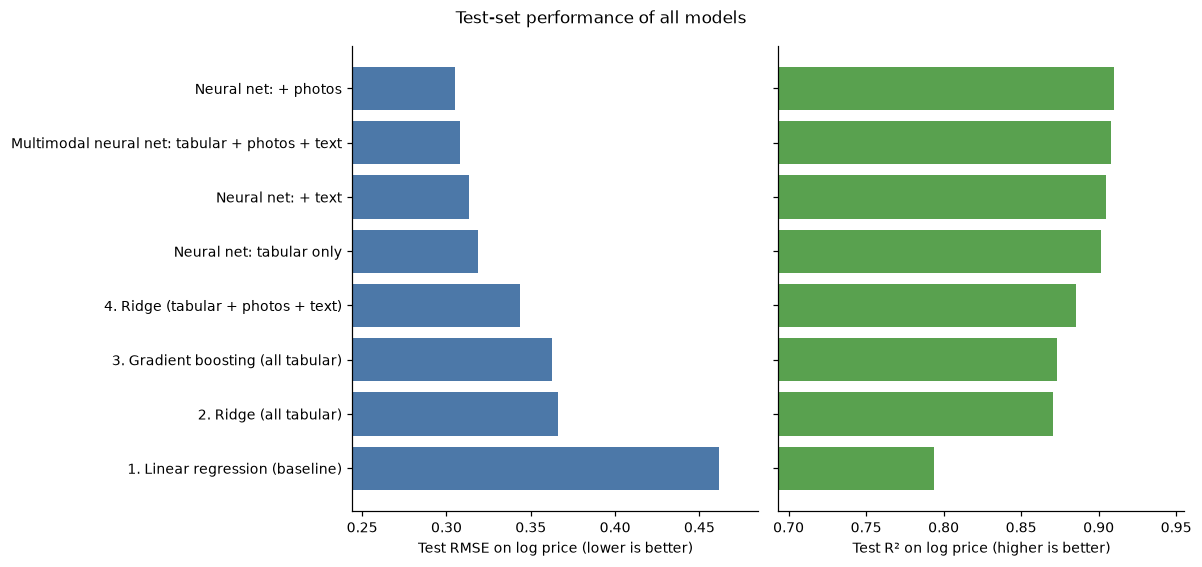

Best model on the validation set: Multimodal neural net: tabular + photos + text
Test RMSE (log) of 'Neural net: + photos' minus tabular-only network: -0.013  (negative = the extra data helped)
Test RMSE (log) of 'Neural net: + text' minus tabular-only network: -0.005  (negative = the extra data helped)
Test RMSE (log) of 'Multimodal neural net: tabular + photos + text' minus tabular-only network: -0.011  (negative = the extra data helped)


In [10]:
order = results["test_RMSE_log"].sort_values(ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(11, 0.45 * len(order) + 1.6))
ax[0].barh(order.index, order.values, color="#4C78A8"); ax[0].set_xlabel("Test RMSE on log price (lower is better)")
ax[1].barh(order.index, results.loc[order.index, "test_R2_log"], color="#59A14F"); ax[1].set_xlabel("Test R² on log price (higher is better)")
ax[1].set_yticklabels([]); ax[0].set_xlim(left=order.min() * 0.8); ax[1].set_xlim(left=max(0, results["test_R2_log"].min() - 0.1))
fig.suptitle("Test-set performance of all models")
save_show("fig_10_model_comparison.png")

best_val = results["val_RMSE_log"].idxmin()
print("Best model on the validation set:", best_val)
if RUN_NN:
    full = "Multimodal neural net: tabular + photos + text"
    for name in ("Neural net: + photos", "Neural net: + text", full):
        d = results.loc[name, "test_RMSE_log"] - results.loc["Neural net: tabular only", "test_RMSE_log"]
        print(f"Test RMSE (log) of '{name}' minus tabular-only network: {d:+.3f}  (negative = the extra data helped)")

## 9 · Checking the residuals

Residuals are `actual − predicted` log price. A healthy model has residuals centred on zero, with no pattern against the predicted value, a roughly bell-shaped histogram and similar spread for cheap and expensive houses. The plots below use the best model (chosen on validation) and the linear baseline for comparison.

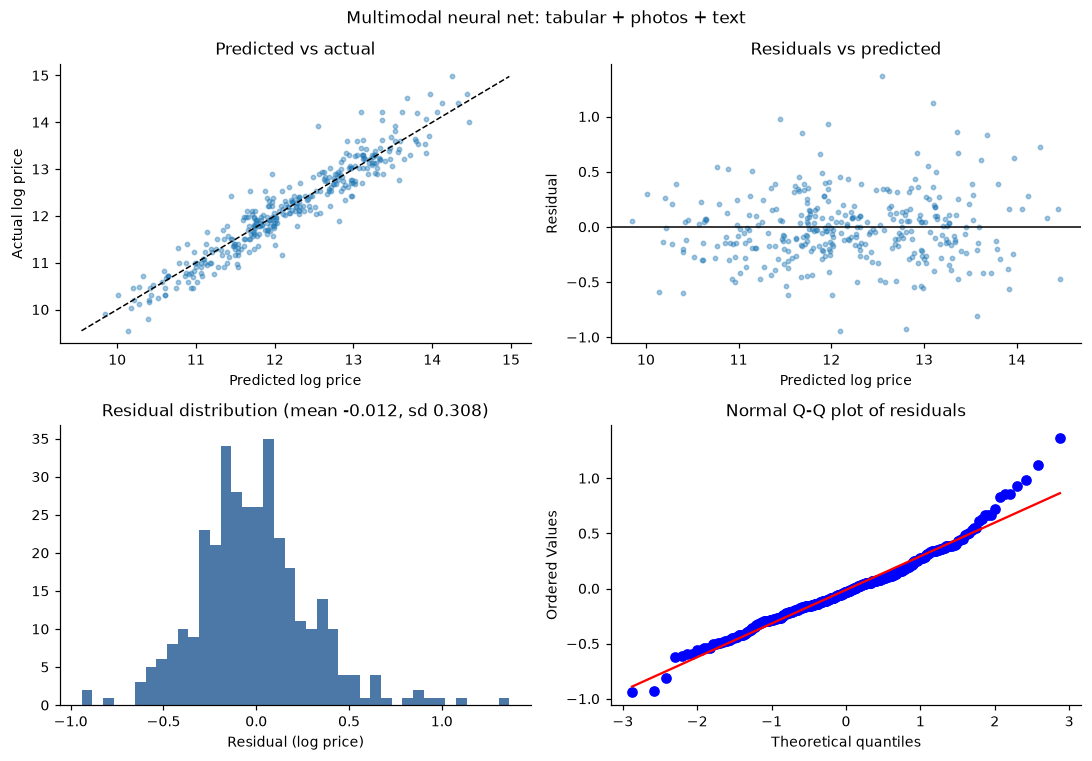

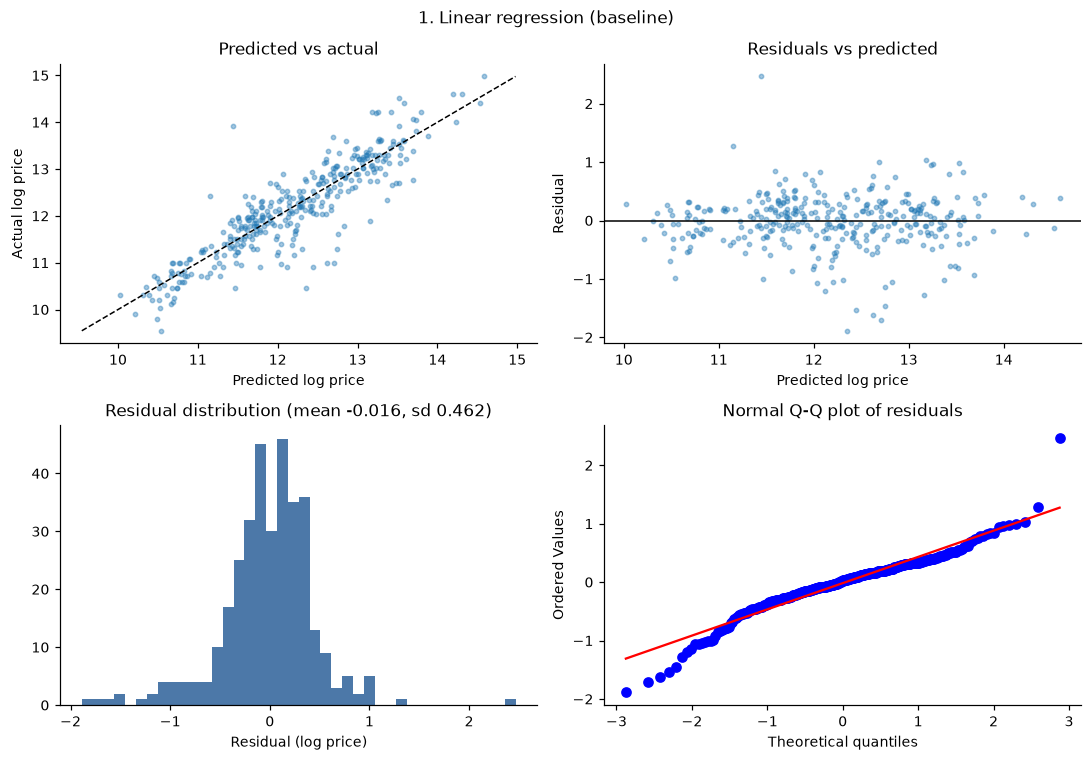

In [11]:
def residual_figure(model_name, file):
    p, a = preds[model_name]["test"], y[test_idx]
    r = a - p
    fig, ax = plt.subplots(2, 2, figsize=(10, 7))
    ax[0, 0].scatter(p, a, s=8, alpha=.4); lim = [min(p.min(), a.min()), max(p.max(), a.max())]
    ax[0, 0].plot(lim, lim, "k--", lw=1); ax[0, 0].set_xlabel("Predicted log price"); ax[0, 0].set_ylabel("Actual log price"); ax[0, 0].set_title("Predicted vs actual")
    ax[0, 1].scatter(p, r, s=8, alpha=.4); ax[0, 1].axhline(0, color="k", lw=1); ax[0, 1].set_xlabel("Predicted log price"); ax[0, 1].set_ylabel("Residual"); ax[0, 1].set_title("Residuals vs predicted")
    ax[1, 0].hist(r, bins=40, color="#4C78A8"); ax[1, 0].set_xlabel("Residual (log price)"); ax[1, 0].set_title(f"Residual distribution (mean {r.mean():.3f}, sd {r.std():.3f})")
    stats.probplot(r, dist="norm", plot=ax[1, 1]); ax[1, 1].set_title("Normal Q-Q plot of residuals")
    fig.suptitle(model_name); save_show(file)

residual_figure(best_val, "fig_11_residuals_best_model.png")
if best_val != LINEAR:
    residual_figure(LINEAR, "fig_12_residuals_baseline.png")

In [12]:
# Is the error the same for cheap and expensive houses, and in every city?
t = houses.iloc[test_idx][["listing_id", "city_clean", "price_usd"]].copy()
t["predicted_usd"] = np.exp(preds[best_val]["test"])
t["pct_error"] = (t["predicted_usd"] - t["price_usd"]) / t["price_usd"] * 100
t["price band"] = pd.cut(t["price_usd"], [0, 100_000, 250_000, 500_000, np.inf], labels=["under $100k", "$100k-250k", "$250k-500k", "over $500k"])
by = lambda col: t.groupby(col, observed=True).agg(houses=("price_usd", "size"), median_abs_pct_error=("pct_error", lambda s: s.abs().median()),
                                                   median_pct_bias=("pct_error", "median")).round(1)
by_band, by_city = by("price band"), by("city_clean")
by_band.to_csv(os.path.join(TAB, "table_error_by_price_band.csv")); by_city.to_csv(os.path.join(TAB, "table_error_by_city.csv"))
print(f"Errors of the best model ({best_val}) on the test set. Bias > 0 means predictions are too high on average.")
display(by_band); display(by_city)

pd.DataFrame({"listing_id": houses["listing_id"].iloc[test_idx].to_numpy(), "actual_usd": np.exp(y[test_idx]),
              **{m: np.exp(d["test"]).round(0) for m, d in preds.items()}}).to_csv(os.path.join(DATA, "test_predictions.csv"), index=False)

Errors of the best model (Multimodal neural net: tabular + photos + text) on the test set. Bias > 0 means predictions are too high on average.


,houses,median_abs_pct_error,median_pct_bias
price band,,,
under $100k,95,18.9,16.0
$100k-250k,118,14.5,1.9
$250k-500k,67,17.2,5.0
over $500k,63,23.4,-10.6


,houses,median_abs_pct_error,median_pct_bias
city_clean,,,
Bulawayo,26,15.9,5.6
Chitungwiza,13,18.5,16.0
Harare,251,16.8,2.9
Other,53,24.4,12.1


## 10 · Which features explain the price?

Two views. **Grouped permutation importance** (gradient boosting, validation houses) shuffles a whole group of columns at once and measures how much worse the predictions become; a bigger increase in error means the group matters more. It answers "which *kinds* of information drive price?". The **ridge coefficients** show the direction and rough size of individual effects. Many amenity and keyword columns overlap (for example `amen_borehole` and `flag_borehole` describe the same feature), so their individual coefficients can have opposite signs; read overlapping columns together, not one by one.

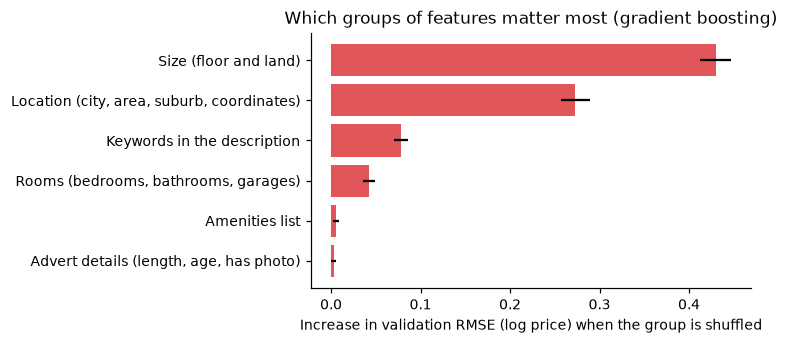

Largest ridge effects, NOT location. Numeric variables are per 1 standard deviation; 0/1 columns mean 'has the feature'.
(Other features held fixed, shrunk towards zero by ridge; 'approx_price_effect_%' = exp(coefficient) - 1.)


,coefficient,approx_price_effect_%
log_land,0.386,47.074001
n_amenities,0.266,30.410000
flag_borehole,0.187,20.540001
garages_not_stated,-0.163,-15.060000
flag_cession,-0.150,-13.931000
amen_water_tank,-0.131,-12.236000
flag_verandah,-0.130,-12.160000
flag_needs_work,-0.129,-12.127000
amen_intercom_system,-0.127,-11.917000
amen_borehole,-0.124,-11.673000


Largest location effects (relative to the average house):


,coefficient,approx_price_effect_%
suburb_grouped_Charlotte Brooke,-1.478,-77.185997
suburb_grouped_Crowhill Views,-1.315,-73.151001
suburb_grouped_Victoria Falls,1.155,217.281998
area_clean_Harare High Density,-0.774,-53.896999
suburb_grouped_Borrowdale Brooke,0.769,115.862999
suburb_grouped_Arlington,0.547,72.738998
suburb_grouped_Glaudina,-0.460,-36.844002
area_clean_Matabeleland North,0.456,57.834000
area_clean_Matabeleland South,0.443,55.754002
area_clean_Harare North,0.416,51.625000


In [13]:
names = F["names"]
groups = {"Location (city, area, suburb, coordinates)": [i for i, n in enumerate(names) if n.startswith(("city_clean", "area_clean", "suburb_grouped", "latitude", "longitude"))],
          "Size (floor and land)": [i for i, n in enumerate(names) if n in ("log_floor", "log_land") or n.endswith(("floor_size_m2_imputed", "land_size_m2_imputed"))],
          "Rooms (bedrooms, bathrooms, garages)": [i for i, n in enumerate(names) if n in ("bedrooms", "bathrooms", "garages", "garages_not_stated", "bathrooms_imputed")],
          "Amenities list": [i for i, n in enumerate(names) if n.startswith("amen_") or n in ("n_amenities", "amenities_listed")],
          "Keywords in the description": [i for i, n in enumerate(names) if n.startswith("flag_")],
          "Advert details (length, age, has photo)": [i for i, n in enumerate(names) if n in ("log_desc_words", "listing_age_days", "has_photo")]}
model = fitted[GBM]; Xv, yv = F["tab"][val_idx], y[val_idx]
base = np.sqrt(np.mean((yv - model.predict(Xv)) ** 2))
rng = np.random.default_rng(SEED); imp = {}
for g, cols in groups.items():
    scores = []
    for _ in range(20):
        Xp = Xv.copy(); Xp[:, cols] = Xp[rng.permutation(len(Xp))][:, cols]
        scores.append(np.sqrt(np.mean((yv - model.predict(Xp)) ** 2)) - base)
    imp[g] = (np.mean(scores), np.std(scores))
imp = pd.DataFrame(imp, index=["increase_in_RMSE_log", "sd"]).T.sort_values("increase_in_RMSE_log")
imp.round(3).to_csv(os.path.join(TAB, "table_group_importance.csv"))
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(imp.index, imp["increase_in_RMSE_log"], xerr=imp["sd"], color="#E15759"); ax.set_xlabel("Increase in validation RMSE (log price) when the group is shuffled")
ax.set_title("Which groups of features matter most (gradient boosting)")
save_show("fig_13_group_importance.png")

ridge = fitted[RIDGE]
coef = pd.Series(ridge.coef_, index=names)
effects = pd.DataFrame({"coefficient": coef, "approx_price_effect_%": (np.exp(coef) - 1) * 100})
is_location = effects.index.str.startswith(("city_clean", "area_clean", "suburb_grouped", "latitude", "longitude"))
by_size = lambda t: t.reindex(t["coefficient"].abs().sort_values(ascending=False).index).head(15).round(3)
other, location = by_size(effects[~is_location]), by_size(effects[is_location])
other.to_csv(os.path.join(TAB, "table_ridge_top_effects_non_location.csv")); location.to_csv(os.path.join(TAB, "table_ridge_top_effects_location.csv"))
print("Largest ridge effects, NOT location. Numeric variables are per 1 standard deviation; 0/1 columns mean 'has the feature'.")
print("(Other features held fixed, shrunk towards zero by ridge; 'approx_price_effect_%' = exp(coefficient) - 1.)")
display(other)
print("Largest location effects (relative to the average house):")
display(location)

## 11 · Limitations

* **Asking prices, not sale prices.** Houses usually sell for less than they are advertised at, and the gap varies; the models predict what sellers ask.
* **A single snapshot.** The listings were collected over a few days in November 2026, so the models say nothing about how prices change over time. Some adverts are older than a year and may be stale.
* **Small dataset.** About 1,600 training houses is little for a neural network. Frozen pretrained features, dropout, early stopping and seed averaging reduce overfitting, but the scores still depend on which houses land in the test set; the cross-validation spread shows by how much.
* **Photos are not standardised.** Agents choose which photos to show (exteriors, interiors, sometimes floor plans or logos), and image quality varies. Averaging up to five photos is a compromise. The pretrained CNN was trained on everyday objects, not on property.
* **Text.** Adverts are short and written in a promotional style, and amounts of money were masked, but not every way of writing a price can be caught (a handful of adverts still contain the price in an unusual form).
* **Location is approximate.** About half the coordinates are suburb averages, and neighbourhood quality within a suburb is not observed.
* **Missing information.** Some values (garages, floor size, bathrooms) had to be filled in; the models are told which values were filled.
* **Near-duplicates.** Different agents may advertise the same house with different wording, so a house could appear in both the training and test sets despite the de-duplication.
* **Dollar errors are dominated by expensive houses**, so RMSE in dollars looks large next to the median percentage error; both are reported.
* **Interpretation.** Importance and coefficients describe association in this data, not what would happen to the price if a feature were added to a house.